# 11) Example: document classification with transformer

> **Task**: consists in *classifying / predicting the subject of a document* into a class.

We will consider the 4 classes: monde, sport, economy, science.

In [1]:
import math, random, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Appareil :', device)

Appareil : cpu


## Dataset

In [6]:
from datasets import load_dataset
from transformers import AutoTokenizer
from sklearn.model_selection import train_test_split

TOKENIZER_NAME = 'bert-base-uncased'  # Textes anglais ; aucun poids BERT chargé.
MAX_LENGTH = 64
N_TRAIN, N_VALID, N_TEST = 6000, 1000, 1000
CACHE = Path('nlp_data')
CACHE.mkdir(exist_ok=True)
tokenizer_cache = str(CACHE / 'tokenizer')
try:
    tokenizer = AutoTokenizer.from_pretrained(
        TOKENIZER_NAME, cache_dir=tokenizer_cache, local_files_only=True)
except OSError:
    tokenizer = AutoTokenizer.from_pretrained(
        TOKENIZER_NAME, cache_dir=tokenizer_cache)
PAD_ID = tokenizer.pad_token_id
VOCAB_SIZE = len(tokenizer)
CLASS_NAMES = ['Monde', 'Sport', 'Économie', 'Science / technologie']

c:\Users\valen\Desktop\Deep Learning UVSQ\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\valen\Desktop\Deep Learning UVSQ\nlp_data\tokenizer\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [7]:
def balanced_indices(labels, n, seed):
    labels = np.asarray(labels)
    assert n % 4 == 0
    rng = np.random.default_rng(seed)
    indices = np.concatenate([
        rng.choice(np.flatnonzero(labels == c), n // 4, replace=False)
        for c in range(4)
    ])
    rng.shuffle(indices)
    return indices.tolist()

def encode_split(data):
    tokens = tokenizer(list(data['text']), padding='max_length',
                       truncation=True, max_length=MAX_LENGTH)
    return {'ids': torch.tensor(tokens['input_ids']),
            'mask': torch.tensor(tokens['attention_mask']).bool(),
            'labels': torch.tensor(list(data['label'])), 'texts': list(data['text'])}

In [8]:
def prepare_ag_news():
    raw = load_dataset('fancyzhx/ag_news', cache_dir=str(CACHE / 'raw'))
    selected = balanced_indices(raw['train']['label'], N_TRAIN + N_VALID, 42)
    labels = np.asarray(raw['train']['label'])[selected]
    train_idx, valid_idx = train_test_split(
        selected, test_size=N_VALID, stratify=labels, random_state=42)
    test_idx = balanced_indices(raw['test']['label'], N_TEST, 43)
    return {name: encode_split(data) for name, data in [
        ('train', raw['train'].select(train_idx)),
        ('valid', raw['train'].select(valid_idx)),
        ('test', raw['test'].select(test_idx))]}

cache_file = CACHE / f'ag_news_bert_{MAX_LENGTH}_{N_TRAIN}_{N_VALID}_{N_TEST}.pt'
if cache_file.exists():
    news = torch.load(cache_file, weights_only=True)
else:
    news = prepare_ag_news()
    torch.save(news, cache_file)
print({name: len(part['labels']) for name, part in news.items()})

c:\Users\valen\Desktop\Deep Learning UVSQ\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\valen\.cache\huggingface\hub\datasets--fancyzhx--ag_news. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\valen\Desktop\Deep Learning UVSQ\.venv\Lib\site-packages\huggingface_hub\file_download.py:149

{'train': 6000, 'valid': 1000, 'test': 1000}


In [ ]:
BATCH_SIZE = 64
D_MODEL, HEADS, LAYERS = 64, 4, 1
EPOCHS, LEARNING_RATE = 30, 1e-3

# instaed than Dataset class, we use here TensorDataset
def tensor_dataset(part):
    return TensorDataset(part['ids'], part['mask'], part['labels'])

def make_train_loader(batch_size=BATCH_SIZE):
    generator = torch.Generator().manual_seed(42)
    return DataLoader(tensor_dataset(news['train']), batch_size=batch_size,
                      shuffle=True, generator=generator, num_workers=0)

valid_loader = DataLoader(tensor_dataset(news['valid']), batch_size=BATCH_SIZE)
test_loader = DataLoader(tensor_dataset(news['test']), batch_size=BATCH_SIZE)
results = {}

In [10]:
for c in range(4):
    i = (news['train']['labels'] == c).nonzero()[0].item()
    print(CLASS_NAMES[c], ':', news['train']['texts'][i][:140])
print('Vocabulaire :', VOCAB_SIZE, '| limite :', MAX_LENGTH, 'tokens')
print('Classes train :', torch.bincount(news['train']['labels']).tolist())

# vocabulary with 30552 terms
# Limite of tokens to be read: 64
# 4 possibles classes: Monde, Sport, Economy, Science

# WE WANT TO TOKENIZE THESE TEXTS AND CLASSIFY THEM AGAIN

Monde : Bearhug Politics: Careful Steps to a New Bush-McCain Alliance George W. Bush and John McCain's bearhug and smooch on the campaign trail last
Sport : Despite effort, Cavs get Sunburn -- The Cavaliers #39; re match against the Phoenix Suns was similar to the previous meeting last month. Tha
Économie : Pilots at Delta take 33pc cut in pay The airline #39;s chief executive Gerald Grinstein describes the pact as a  quot;crucial step quot; in 
Science / technologie : News and Trends Yesterday we noted that more and more companies are heading to the courts to sue other companies in intellectual property di
Vocabulaire : 30522 | limite : 64 tokens
Classes train : [1500, 1500, 1500, 1500]


### Masks

In [11]:
ids, mask, labels = next(iter(make_train_loader()))
print('Entrées :', ids.shape, '| masque :', mask.shape, '| cibles :', labels.shape)
print(tokenizer.convert_ids_to_tokens(ids[0, mask[0]].tolist()))
print('Texte normalisé :', tokenizer.decode(ids[0, mask[0]].tolist()))

Entrées : torch.Size([64, 64]) | masque : torch.Size([64, 64]) | cibles : torch.Size([64])
['[CLS]', 'ibm', 'regain', '##s', 'speed', 'lead', 'the', 'latest', 'machine', 'for', 'helping', 'the', 'energy', 'department', 'model', 'nuclear', 'explosions', 'has', 'become', 'the', 'world', '#', '39', ';', 's', 'most', 'powerful', 'computer', '.', 'an', 'ibm', 'corp', '.', '[SEP]']
Texte normalisé : [CLS] ibm regains speed lead the latest machine for helping the energy department model nuclear explosions has become the world # 39 ; s most powerful computer. an ibm corp. [SEP]


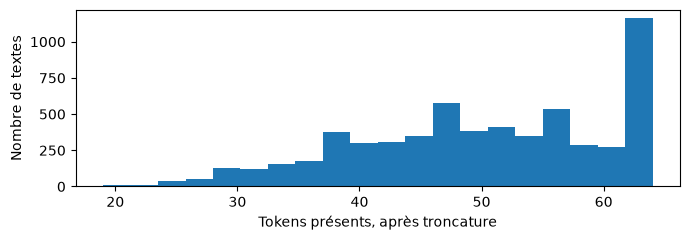

In [12]:
lengths = news['train']['mask'].sum(dim=1).numpy()
plt.figure(figsize=(7, 2.5))
plt.hist(lengths, bins=20)
plt.xlabel('Tokens présents, après troncature')
plt.ylabel('Nombre de textes')
plt.tight_layout()
plt.show()

### Ex: mean of masked embedded tokens

*Mask*: a list of 1 and 0 on the text, which tells if token or padding.

--> *Masked term*: a 'real' token referred to / masked as 1.

In [28]:
def masked_mean(x, mask):
    # X : size (B, T, C)
    # mask : size (B, T); type 'bool': True for real token and False for padding
    weights = mask.unsqueeze(-1).to(x.dtype)

    # SUM ON TENSORS
    total = (x*weights).sum(dim=1)              # TODO 1a : somme pondérée sur les positions.
    count = weights.sum(dim=1)                  # TODO 1b : somme des poids sur les positions.
    if total is None or count is None:
        raise NotImplementedError('TODO 1 : moyenne sans padding')
    return total / count.clamp_min(1)

In [27]:
x_check = torch.tensor([[[2., 4.], [4., 8.], [100., 100.]]])
mask_check = torch.tensor([[True, True, False]])
assert torch.allclose(masked_mean(x_check, mask_check), torch.tensor([[3., 6.]]))
assert masked_mean(x_check, mask_check).shape == (1, 2)
print('La valeur PAD ne contribue pas à la moyenne.')

La valeur PAD ne contribue pas à la moyenne.


## Mean of embeddings

### Ex: Classifier

In [33]:
class AverageClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(VOCAB_SIZE, D_MODEL, padding_idx=PAD_ID)
        self.head = nn.Linear(D_MODEL, 4)       # TODO 2a : couche linéaire vers les quatre classes.

    def forward(self, ids, mask):
        x = self.embedding(ids)
        x = masked_mean(x, mask)                # TODO 2b : masked mean
        return self.head(x)

In [37]:
baseline = AverageClassifier()
with torch.no_grad():
    logits = baseline(ids, mask)
assert logits.shape == (len(ids), 4)
print('Sortie :', logits.shape)                                         # logists classified
print('Paramètres :', sum(p.numel() for p in baseline.parameters()))    # total number of parameters

print(D_MODEL, VOCAB_SIZE)

Sortie : torch.Size([64, 4])
Paramètres : 1953668
64 30522


### Ex: cross entropy loss and one step of training

In [38]:
criterion = nn.CrossEntropyLoss()             # TODO 3a : créer la perte multiclasse.

def classification_step(model, optimizer, ids, mask, labels):
    optimizer.zero_grad(set_to_none=True)
    logits = model(ids, mask)
    loss = criterion(logits, labels)         # TODO 3b : calculer la perte.
    
    if criterion is None or loss is None:
        raise NotImplementedError('TODO 3 : entropie croisée, gradient et mise à jour')
    loss.backward()                         # TODO 3c : rétropropager la perte.
    optimizer.step()                        # TODO 3d : mettre à jour les paramètres.
    return loss.item()

In [39]:
probe = AverageClassifier().to(device)
probe_optimizer = torch.optim.AdamW(probe.parameters(), lr=LEARNING_RATE)
before = probe.head.weight.detach().clone()
loss_value = classification_step(probe, probe_optimizer, ids.to(device),
                                 mask.to(device), labels.to(device))
assert math.isfinite(loss_value)
assert probe.head.weight.grad is not None, 'Il manque backward.'
assert not torch.equal(before, probe.head.weight), 'Les poids ne sont pas mis à jour.'
print('Un pas calcule les gradients et modifie les poids.')

Un pas calcule les gradients et modifie les poids.


### Training and validation of classifier

In [40]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, count = 0., 0, 0
    for ids, mask, labels in loader:
        ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
        logits = model(ids, mask)
        loss_sum += criterion(logits, labels).item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += len(labels)
    return loss_sum / count, correct / count

def train_epoch(model, optimizer, loader):
    model.train()
    total, count = 0., 0
    for ids, mask, labels in loader:
        loss = classification_step(model, optimizer, ids.to(device),
                                   mask.to(device), labels.to(device))
        total += loss * len(labels)
        count += len(labels)
    return total / count

In [41]:
def best_checkpoint(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

def finish_fit(model, weights, history, epoch, start):
    synchronize()
    seconds = time.perf_counter() - start
    model.load_state_dict(weights)
    return {'model': model, 'history': np.asarray(history),
            'best_epoch': epoch, 'seconds': seconds,
            'parameters': sum(p.numel() for p in model.parameters())}

def synchronize():
    if device.type == 'cuda':
        torch.cuda.synchronize()

In [42]:
def fit(model_class, name, *, epochs=EPOCHS, learning_rate=LEARNING_RATE,
        batch_size=BATCH_SIZE, weight_decay=0.01):
    set_seed()
    model = model_class().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    loader = make_train_loader(batch_size=batch_size)
    validation_loader = DataLoader(tensor_dataset(news['valid']), batch_size=batch_size)
    history, best_loss, weights = [], float('inf'), None
    synchronize()
    start = time.perf_counter()
    for epoch in range(epochs):
        train_loss = train_epoch(model, optimizer, loader)
        valid_loss, accuracy = evaluate(model, validation_loader)
        history.append((train_loss, valid_loss, accuracy))
        if valid_loss < best_loss:
            best_loss, best_epoch = valid_loss, epoch + 1
            weights = best_checkpoint(model)
        print(f'{name} : {epoch + 1} | validation : {accuracy:.1%}')
    return finish_fit(model, weights, history, best_epoch, start)

In [43]:
def plot_history(result):
    history = result['history']
    epochs = np.arange(1, len(history) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].plot(epochs, history[:, 0], label='Entraînement')
    axes[0].plot(epochs, history[:, 1], label='Validation')
    axes[0].set_ylabel('Entropie croisée')
    axes[0].legend()
    axes[1].plot(epochs, history[:, 2])
    axes[1].set_ylabel('Accuracy de validation')
    axes[1].set_ylim(0, 1)
    for ax in axes:
        ax.set_xlabel('Époque')
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Moyenne : 1 | validation : 46.7%
Moyenne : 2 | validation : 61.1%
Moyenne : 3 | validation : 69.0%
Moyenne : 4 | validation : 73.8%
Moyenne : 5 | validation : 77.3%
Moyenne : 6 | validation : 80.1%
Moyenne : 7 | validation : 82.0%
Moyenne : 8 | validation : 82.8%
Moyenne : 9 | validation : 83.1%
Moyenne : 10 | validation : 84.1%
Moyenne : 11 | validation : 84.4%
Moyenne : 12 | validation : 84.8%
Moyenne : 13 | validation : 85.3%
Moyenne : 14 | validation : 85.1%
Moyenne : 15 | validation : 85.6%
Moyenne : 16 | validation : 86.1%
Moyenne : 17 | validation : 86.3%
Moyenne : 18 | validation : 86.3%
Moyenne : 19 | validation : 86.3%
Moyenne : 20 | validation : 86.5%
Moyenne : 21 | validation : 86.6%
Moyenne : 22 | validation : 86.6%
Moyenne : 23 | validation : 86.7%
Moyenne : 24 | validation : 86.7%
Moyenne : 25 | validation : 86.7%
Moyenne : 26 | validation : 86.6%
Moyenne : 27 | validation : 86.4%
Moyenne : 28 | validation : 86.3%
Moyenne : 29 | validation : 86.1%
Moyenne : 30 | validati

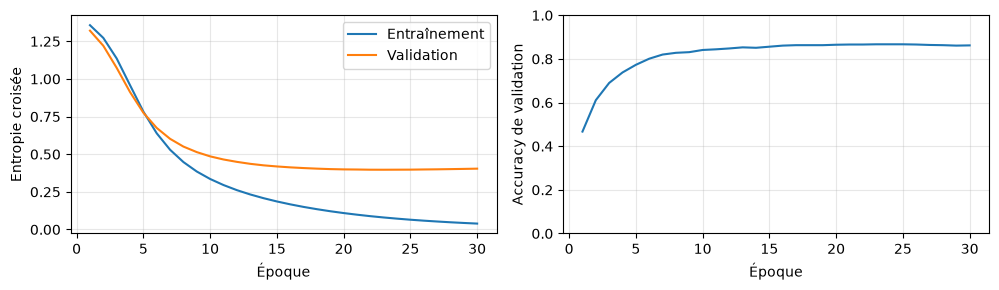

In [44]:
results['Moyenne'] = fit(AverageClassifier, 'Moyenne')
plot_history(results['Moyenne'])

## Ex : CNNs of 1 dimension : Conv1d

In [64]:
def cnn_layers():

    # TODO 4a : Conv1d (noyau 5, longueur conservée), puis ReLU.
    first = nn.Sequential(
        nn.Conv1d(D_MODEL, D_MODEL, kernel_size=5, padding='same'),      # input channel, output channel
        nn.ReLU(),
    )

    # TODO 4b : Conv1d (noyau 3, longueur conservée), puis ReLU.
    second = nn.Sequential(
        nn.Conv1d(D_MODEL, D_MODEL, kernel_size=3, padding='same'),
        nn.ReLU(),
    )

    if first is None or second is None:
        raise NotImplementedError('TODO 4 : deux blocs convolutifs')
    return first, second

def cnn_features(model, x, mask):

    x = x.transpose(1,2)     # TODO 4c : transposer les axes des positions et des canaux de (B, T, C) à (B, C, T).

    if x is None:
        raise NotImplementedError('TODO 4c : tenseur (B, C, T)')
    weights = mask.unsqueeze(1).to(x.dtype)
    x = model.conv1(x) * weights
    x = model.conv2(x) * weights

    return x.transpose(1,2)    # TODO 4d : transposer à l'invers de (B, C, T) à (B, T, C)


In [74]:
class CNNClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(VOCAB_SIZE, D_MODEL, padding_idx=PAD_ID)
        self.conv1, self.conv2 = cnn_layers()
        self.head = nn.Linear(D_MODEL, 4)

    def forward(self, ids, mask):
        x = self.embedding(ids)
        x = cnn_features(self, x, mask)
        return self.head(masked_mean(x, mask))

with torch.no_grad():
    assert CNNClassifier()(ids, mask).shape == (len(ids), 4)
print('Dimensions CNN correctes.')

# TODO 4e : calculer le nombre de paramètres de ce modèle
CNNClassifier = CNNClassifier()
num_params = sum(p.numel() for p in CNNClassifier.parameters())
print(num_params)

Dimensions CNN correctes.
1986564


CNN : 1 | validation : 59.0%
CNN : 2 | validation : 68.6%
CNN : 3 | validation : 75.6%
CNN : 4 | validation : 76.9%
CNN : 5 | validation : 79.0%
CNN : 6 | validation : 79.1%
CNN : 7 | validation : 79.9%
CNN : 8 | validation : 80.4%
CNN : 9 | validation : 80.5%
CNN : 10 | validation : 81.0%
CNN : 11 | validation : 81.6%
CNN : 12 | validation : 81.3%
CNN : 13 | validation : 81.5%
CNN : 14 | validation : 82.0%
CNN : 15 | validation : 82.0%
CNN : 16 | validation : 81.8%
CNN : 17 | validation : 81.9%
CNN : 18 | validation : 82.0%
CNN : 19 | validation : 81.9%
CNN : 20 | validation : 82.1%
CNN : 21 | validation : 82.2%
CNN : 22 | validation : 82.0%
CNN : 23 | validation : 82.1%
CNN : 24 | validation : 82.1%
CNN : 25 | validation : 82.2%
CNN : 26 | validation : 82.2%
CNN : 27 | validation : 82.3%
CNN : 28 | validation : 82.1%
CNN : 29 | validation : 82.0%
CNN : 30 | validation : 82.0%


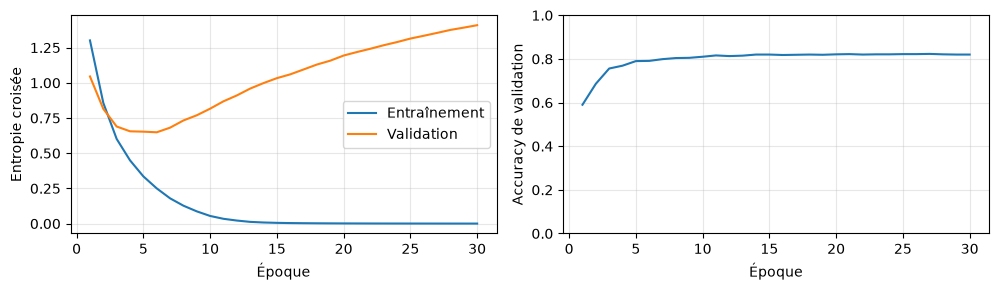

In [66]:
results['CNN'] = fit(CNNClassifier, 'CNN')
plot_history(results['CNN'])

We have *overfitting*.  We have two forms of regularization:
1) dropout
2) weights decay

## Ex: Transformers

### MicroGPT code

In [67]:
def rms_norm(x):
    return x * torch.rsqrt(x.square().mean(dim=-1, keepdim=True) + 1e-5)

def split_heads(x, heads):
    # (T, C) -> (H, T, d), ou (B, T, C) -> (B, H, T, d).
    *prefix, T, C = x.shape
    return x.reshape(*prefix, T, heads, C // heads).transpose(-3, -2)

def merge_heads(x):
    # Opération inverse ; conserver le batch éventuel.
    *prefix, H, T, d = x.shape
    return x.transpose(-3, -2).contiguous().view(*prefix, T, H * d)

In [68]:
def attention_weights(q, k, causal=True, mask=None):
    # q, k : (..., H, T, d), avec un batch éventuel avant les H têtes.
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))
    if causal:
        T = q.size(-2)
        # tril = triangular lower = matrice triangulaire inférieure.
        allowed = torch.ones(T, T, dtype=torch.bool, device=q.device).tril()
        scores = scores.masked_fill(~allowed, float('-inf'))
    if mask is not None:
        # mask : (..., T), True sur les tokens présents ; masquer les clés PAD.
        scores = scores.masked_fill(~mask[..., None, None, :], float('-inf'))
    return scores.softmax(dim=-1)

In [69]:
class SelfAttention(nn.Module):
    def __init__(self, d_model, heads, causal=True):
        super().__init__()
        assert d_model % heads == 0
        self.heads, self.causal = heads, causal
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)
        self.proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x, mask=None):
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q, k, v = [split_heads(z, self.heads) for z in (q, k, v)]
        weights = attention_weights(q, k, causal=self.causal, mask=mask)
        self.last_weights = weights.detach()  # Pour l'affichage seulement.
        return self.proj(merge_heads(weights @ v))

In [70]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, heads, causal=True):
        super().__init__()
        self.attn = SelfAttention(d_model, heads, causal=causal)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, 4 * d_model, bias=False),
            nn.ReLU(),
            nn.Linear(4 * d_model, d_model, bias=False))

    def forward(self, x, mask=None):
        x = x + self.attn(rms_norm(x), mask=mask)
        x = x + self.mlp(rms_norm(x))
        return x

In [79]:
# LIST OF MODULES
def make_encoder():
    return nn.ModuleList([
        TransformerBlock(D_MODEL, HEADS, causal=False) for _ in range(LAYERS)])

def contextualize(model, x, mask):
    # X : size (B, T, C)

    # TODO 5a : ajouter les embeddings de positions à x.
    positions = torch.arange(x.size(1), device=x.device)
    pos_embed = model.positions(positions)
    x = x + pos_embed.unsqueeze(0)    

    if x is None:
        raise NotImplementedError('TODO 5a : tokens + positions')

    for block in model.encoder:
        x = block(x, mask=mask)     # TODO 5b : appliquer le bloc à x avec le masque des tokens présents.

    return rms_norm(x)

In [80]:
class TransformerClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(VOCAB_SIZE, D_MODEL, padding_idx=PAD_ID)
        self.positions = nn.Embedding(MAX_LENGTH, D_MODEL)
        self.encoder = make_encoder()
        self.head = nn.Linear(D_MODEL, 4)

    def forward(self, ids, mask):
        x = self.embedding(ids)
        x = contextualize(self, x, mask)
        return self.head(masked_mean(x, mask))

In [81]:
with torch.no_grad():
    assert TransformerClassifier()(ids, mask).shape == (len(ids), 4)
print('Dimensions transformer correctes.')

Dimensions transformer correctes.


Transformer : 1 | validation : 54.1%
Transformer : 2 | validation : 67.2%
Transformer : 3 | validation : 74.5%
Transformer : 4 | validation : 76.9%
Transformer : 5 | validation : 77.9%
Transformer : 6 | validation : 79.8%
Transformer : 7 | validation : 79.6%
Transformer : 8 | validation : 80.4%
Transformer : 9 | validation : 80.5%
Transformer : 10 | validation : 80.2%
Transformer : 11 | validation : 80.7%
Transformer : 12 | validation : 80.6%
Transformer : 13 | validation : 79.8%
Transformer : 14 | validation : 80.0%
Transformer : 15 | validation : 80.0%
Transformer : 16 | validation : 80.1%
Transformer : 17 | validation : 80.2%
Transformer : 18 | validation : 80.2%
Transformer : 19 | validation : 80.3%
Transformer : 20 | validation : 80.1%
Transformer : 21 | validation : 80.2%
Transformer : 22 | validation : 80.4%
Transformer : 23 | validation : 80.4%
Transformer : 24 | validation : 80.1%
Transformer : 25 | validation : 80.2%
Transformer : 26 | validation : 80.2%
Transformer : 27 | va

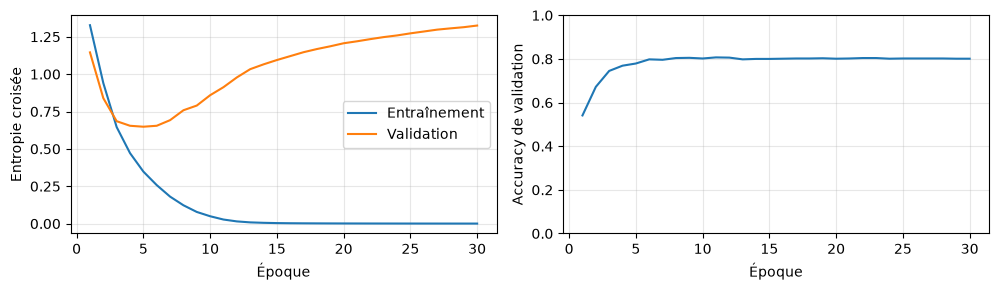

In [82]:
results['Transformer'] = fit(TransformerClassifier, 'Transformer')
plot_history(results['Transformer'])

## Comparison of the 3 models

In [83]:
for name, result in results.items():
    _, accuracy = evaluate(result['model'], valid_loader)
    embeddings = result['model'].embedding.weight.numel()
    print(f'{name:12s} | validation {accuracy:.1%}')
    print(f"  {result['parameters']:,} paramètres, dont {embeddings:,} embeddings")
    print(f"  {result['seconds']:.1f} s ; époque retenue : {result['best_epoch']}")

Moyenne      | validation 86.7%
  1,953,668 paramètres, dont 1,953,408 embeddings
  47.9 s ; époque retenue : 23
CNN          | validation 79.1%
  1,986,564 paramètres, dont 1,953,408 embeddings
  84.1 s ; époque retenue : 6
Transformer  | validation 77.9%
  2,006,916 paramètres, dont 1,953,408 embeddings
  190.3 s ; époque retenue : 5


In [84]:
def shuffled_validation():
    part = news['valid']
    shuffled = part['ids'].clone()
    generator = torch.Generator().manual_seed(123)
    for row, mask_row in enumerate(part['mask']):
        positions = mask_row.nonzero().flatten()[1:-1]  # Garder CLS et SEP.
        permutation = torch.randperm(len(positions), generator=generator)
        shuffled[row, positions] = part['ids'][row, positions[permutation]]
    data = TensorDataset(shuffled, part['mask'], part['labels'])
    return DataLoader(data, batch_size=BATCH_SIZE)

shuffle_loader = shuffled_validation()
for name, result in results.items():
    _, normal = evaluate(result['model'], valid_loader)
    _, shuffled = evaluate(result['model'], shuffle_loader)
    print(f'{name:12s} | original {normal:.1%} | mélangé {shuffled:.1%}')

Moyenne      | original 86.7% | mélangé 86.7%
CNN          | original 79.1% | mélangé 78.6%
Transformer  | original 77.9% | mélangé 78.1%
